Note: this was not used for the manuscript.

# Align Spatial Transcriptomics to the Allen Brain Atlas with STalign

This notebook walks through aligning AnnData spatial transcriptomics sections to the
[Allen Brain Atlas CCFv3](https://atlas.brain-map.org/) using
[STalign](https://github.com/JEFworks-Lab/STalign), and annotating each cell with its
brain region label.

**Reference:** Clifton, Anant et al. *Nature Communications* 14, 8123 (2023).

**What this notebook does:**
1. Downloads and caches the Allen Brain Atlas CCFv3 (Nissl + annotations)
2. Loads your AnnData and extracts cell coordinates
3. Rasterizes cell positions into a density image
4. Lets you browse atlas slices to find the correct coronal position
5. Runs STalign's LDDMM 3D-to-2D alignment
6. Projects atlas region labels onto every cell
7. Writes annotated results back to AnnData

**Runtime:** ~15–45 min per section on CPU; faster with `cuda`.

## 1. Imports and setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import torch
import nrrd
import anndata as ad
from pathlib import Path
from scipy.ndimage import rotate

from STalign import STalign

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 10)
plt.rcParams['figure.dpi'] = 100

print('torch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

torch: 2.0.0+cu117
CUDA available: True


## 2. Configuration

Edit the paths and parameters below to match your data.

In [2]:
# ── Paths to your AnnData files ──────────────────────────────────────
# Add as many sections as you have
ADATA_PATHS = [
    '/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad',
    '/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad',
]

# ── Where cell coordinates live in your AnnData ─────────────────────
# Option A: columns in adata.obs
X_COL = None   # set to None to use obsm['spatial']
Y_COL = None   # set to None to use obsm['spatial']

# Option B: if X_COL/Y_COL are None, the script uses:
#   adata.obsm['spatial'][:, 0]  (x)
#   adata.obsm['spatial'][:, 1]  (y)

# ── Coordinate scale ────────────────────────────────────────────────
# Per-section scale factors
# MERFISH (Vizgen): coordinates already in microns
# STARmap PLUS (Wang lab): voxel size = 194 nm → multiply by 0.194

SCALE_FACTORS = [
    1.0,    # section 1 — MERFISH (already in µm)
    0.194,  # section 2 — STARmap PLUS (pixels → µm)
]

# ── Atlas cache directory ────────────────────────────────────────────
ATLAS_DIR = Path('atlas_cache')

# ── Device ───────────────────────────────────────────────────────────
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')

Using device: cuda:0


## 3. Download the Allen Brain Atlas

This downloads ~200 MB of atlas data on first run and caches it locally.
Subsequent runs skip the download.

In [3]:
ATLAS_DIR.mkdir(parents=True, exist_ok=True)

# Allen Brain Atlas CCFv3 URLs (adult mouse P56, 50 µm resolution)
ONTOLOGY_URL = (
    'http://api.brain-map.org/api/v2/data/query.csv?'
    'criteria=model::Structure,'
    'rma::criteria,[ontology_id$eq1],'
    'rma::options[order$eq%27structures.graph_order%27][num_rows$eqall]'
)
NISSL_URL = (
    'http://download.alleninstitute.org/informatics-archive/'
    'current-release/mouse_ccf/ara_nissl/ara_nissl_50.nrrd'
)
LABEL_URL = (
    'http://download.alleninstitute.org/informatics-archive/'
    'current-release/mouse_ccf/annotation/ccf_2017/annotation_50.nrrd'
)

ontology_file = str(ATLAS_DIR / 'allen_ontology.csv')
nissl_file    = str(ATLAS_DIR / 'aba_nissl.nrrd')
label_file    = str(ATLAS_DIR / 'aba_annotation.nrrd')

print('Downloading ontology...')
ontology_name, namesdict = STalign.download_aba_ontology(ONTOLOGY_URL, ontology_file)

print('Downloading Nissl volume + annotations (~200 MB)...')
imagefile, labelfile = STalign.download_aba_image_labels(
    NISSL_URL, LABEL_URL, nissl_file, label_file
)

print('Done! Atlas files cached in:', ATLAS_DIR)

<Response [200]>
Done! Atlas files cached in: atlas_cache


## 4. Load the atlas volume

Read the 3D Nissl image and annotation volumes. The Nissl volume is used for
image-based alignment; the annotation volume contains the region labels.

In [4]:
vol_nissl, hdr = nrrd.read(imagefile)
A_atlas = vol_nissl

vol_labels, _ = nrrd.read(labelfile)

dxA = np.diag(hdr['space directions'])
nxA = A_atlas.shape
xA = [np.arange(n) * d - (n - 1) * d / 2.0 for n, d in zip(nxA, dxA)]

print(f'Atlas volume shape: {A_atlas.shape}')
print(f'Voxel size: {dxA} µm')
print(f'Slice range: 0 (anterior) to {A_atlas.shape[0] - 1} (posterior)')

Atlas volume shape: (264, 160, 228)
Voxel size: [50. 50. 50.] µm
Slice range: 0 (anterior) to 263 (posterior)


## 5. Browse atlas slices to find matching coronal positions

Scroll through these to find which atlas slice number best matches each of
your tissue sections. Adjust `start` and `end` to narrow down.

For the Allen Reference Atlas plate `100960224` (structure 549), this is
approximately **slice ≈ 177** in the 50 µm CCFv3 volume.

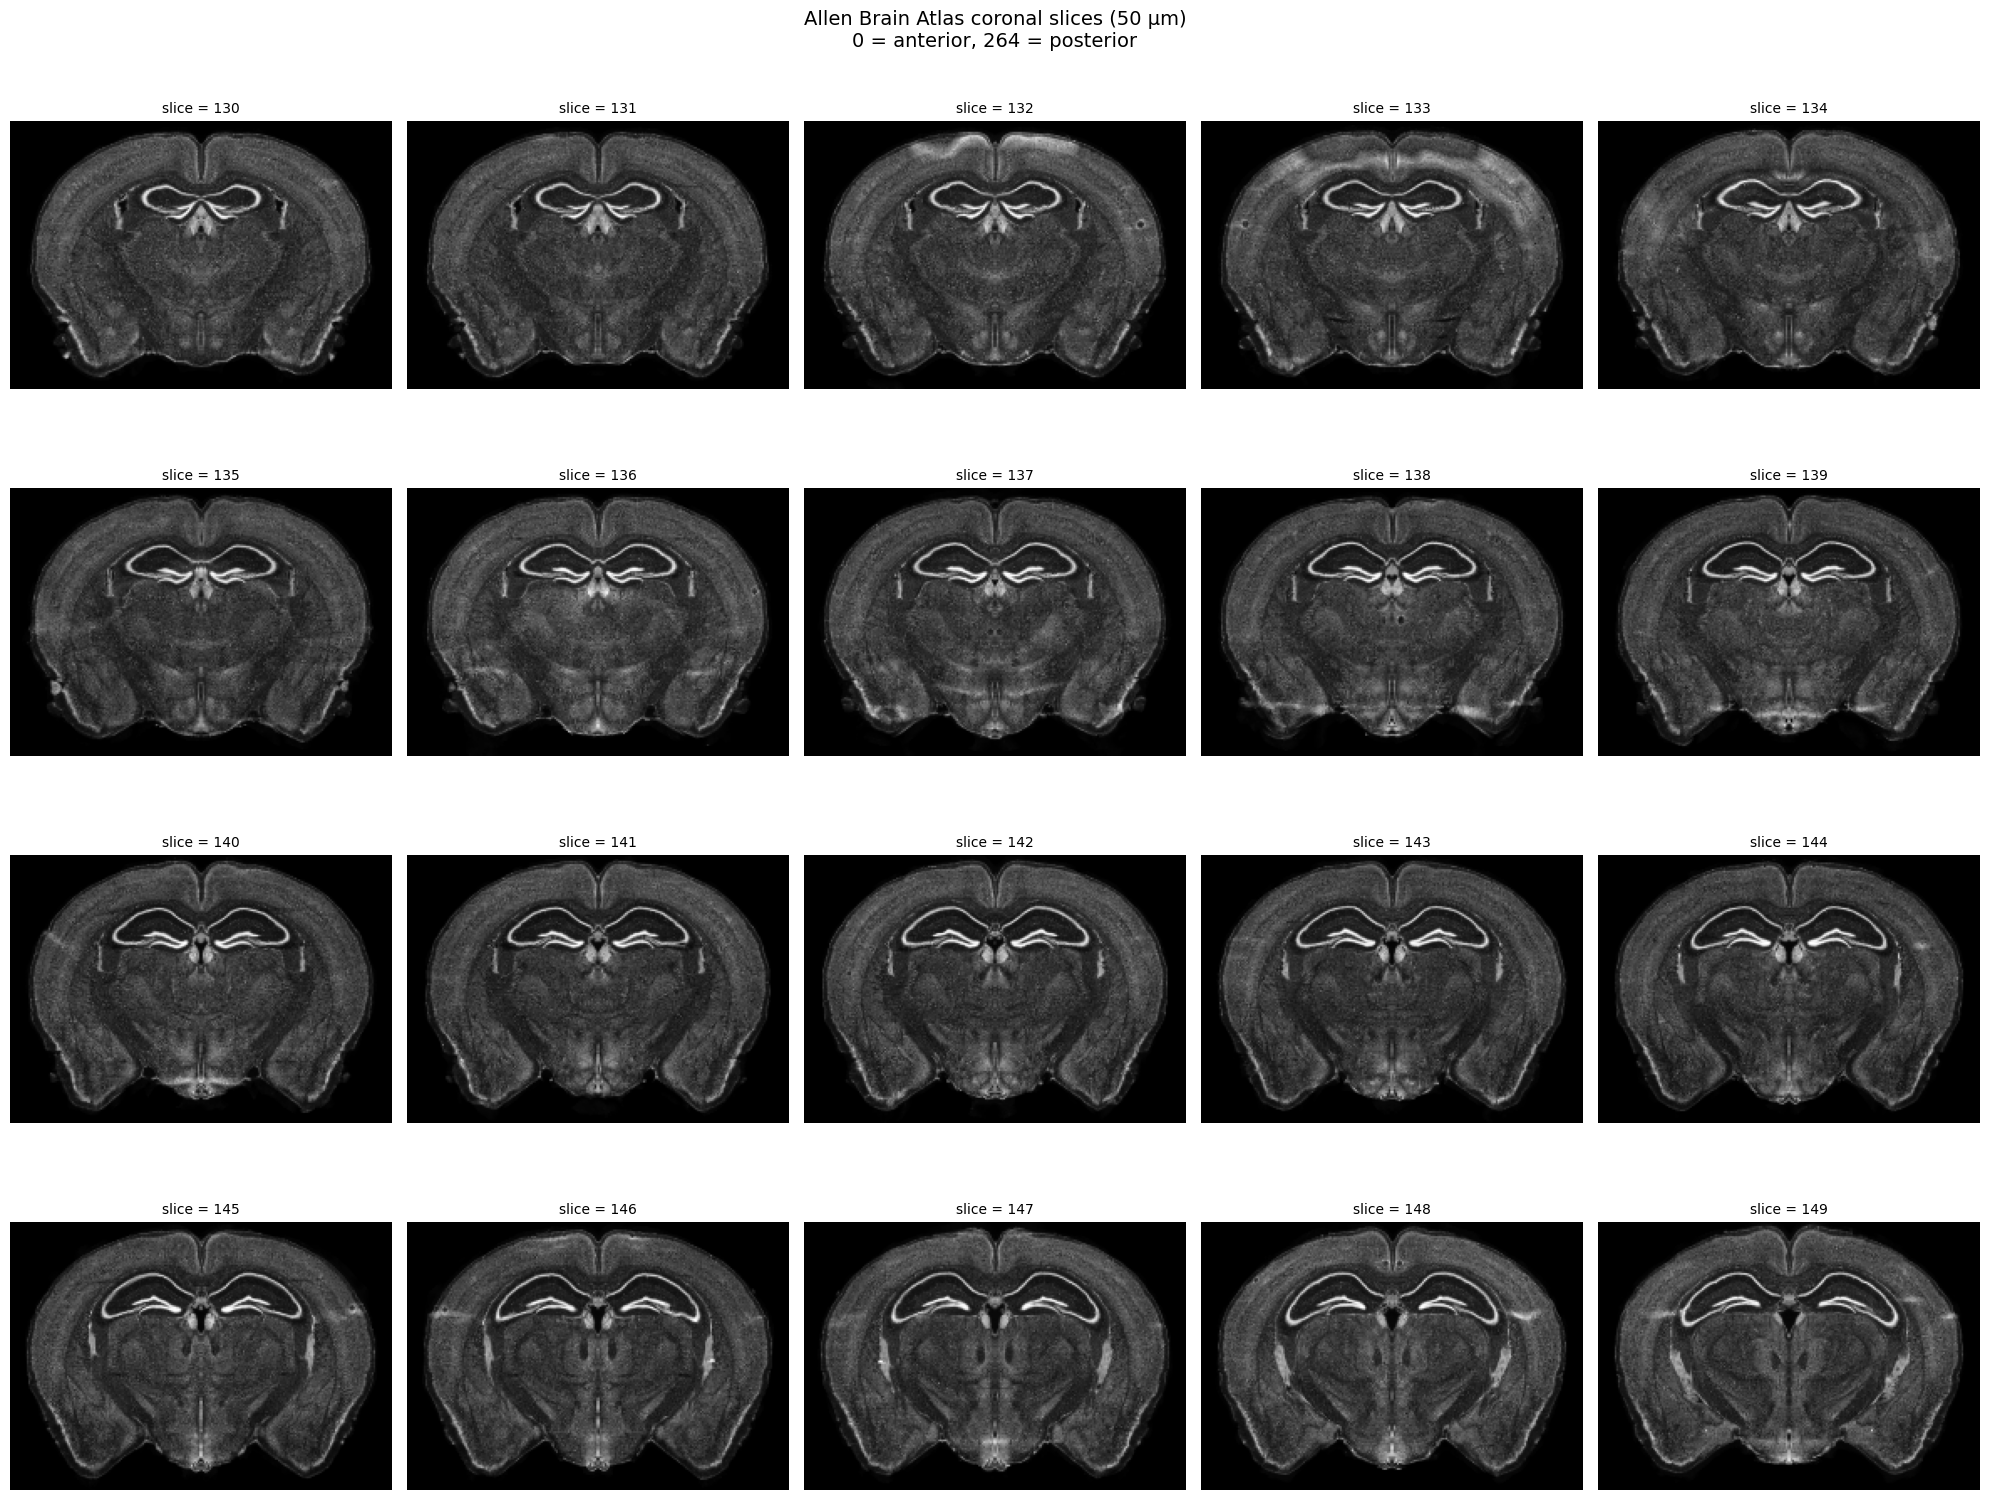

In [5]:
start, end, step = 130, 150, 1  # adjust range as needed

slices = list(range(start, end, step))
ncols = 5
nrows = (len(slices) + ncols - 1) // ncols

extentA = STalign.extent_from_x(xA[1:])

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = axes.flatten()
for i, s in enumerate(slices):
    axes[i].imshow(A_atlas[s], extent=extentA, cmap='gray')
    axes[i].set_title(f'slice = {s}', fontsize=10)
    axes[i].axis('off')
for i in range(len(slices), len(axes)):
    axes[i].axis('off')

fig.suptitle('Allen Brain Atlas coronal slices (50 µm)\n'
             '0 = anterior, 264 = posterior', fontsize=14)
plt.tight_layout()
plt.show()

## 6. Set the atlas slice for each section

Based on the atlas browser above, assign the best-matching slice index
for each of your tissue sections.

In [6]:
# ── Atlas slice per section ──────────────────────────────────────────
# Must have the same number of entries as ADATA_PATHS
ATLAS_SLICES = [
    140,  # section 1
    140,  # section 2
]

## 7. Load AnnData and extract coordinates

We load each section and pull out the cell x/y positions. Run this cell
to verify the coordinates look right.

In [7]:
def extract_coords(adata, x_col=None, y_col=None, scale=1.0):
    """Extract cell x, y coordinates from AnnData."""
    if x_col and y_col and x_col in adata.obs.columns and y_col in adata.obs.columns:
        x = np.array(adata.obs[x_col].values, dtype=float) * scale
        y = np.array(adata.obs[y_col].values, dtype=float) * scale
        src = f'adata.obs[\'{x_col}\'] / adata.obs[\'{y_col}\']'
    elif 'spatial' in adata.obsm:
        x = np.array(adata.obsm['spatial'][:, 0], dtype=float) * scale
        y = np.array(adata.obsm['spatial'][:, 1], dtype=float) * scale
        src = "adata.obsm['spatial']"
    else:
        raise ValueError(
            f'Cannot find spatial coordinates.\n'
            f'Available .obs columns: {list(adata.obs.columns)}\n'
            f'Available .obsm keys: {list(adata.obsm.keys())}'
        )
    print(f'  Source: {src}')
    print(f'  {len(x):,} cells, x: [{x.min():.1f}, {x.max():.1f}], '
          f'y: [{y.min():.1f}, {y.max():.1f}]')
    return x, y

In [8]:
def rotate_coords(x, y, angle_deg):
    """Rotate coordinates by angle_deg (counterclockwise) around their centroid."""
    theta = np.radians(angle_deg)
    cx, cy = x.mean(), y.mean()
    x_c, y_c = x - cx, y - cy
    x_rot = x_c * np.cos(theta) - y_c * np.sin(theta) + cx
    y_rot = x_c * np.sin(theta) + y_c * np.cos(theta) + cy
    return x_rot, y_rot

In [9]:
# ── Per-section rotation (degrees, counterclockwise) ─────────────────
ROTATIONS = [
    180,   # section 1 — MERFISH (upside-down)
    90,   # section 2 — STARmap PLUS (90° clockwise)
]

adatas = []
coords = []
for i, (path, sf, rot) in enumerate(zip(ADATA_PATHS, SCALE_FACTORS, ROTATIONS)):
    print(f'\n── Section {i+1}: {path} (scale={sf}, rotate={rot}°) ──')
    adata = ad.read_h5ad(path)
    print(f'  Shape: {adata.shape[0]:,} cells × {adata.shape[1]:,} genes')
    x, y = extract_coords(adata, X_COL, Y_COL, sf)
    
    # Rotate coordinates
    if rot != 0:
        x, y = rotate_coords(x, y, rot)
        print(f'  After rotation: x: [{x.min():.1f}, {x.max():.1f}], '
              f'y: [{y.min():.1f}, {y.max():.1f}]')
    
    # Verify the scaled span is reasonable
    span = max(x.max()-x.min(), y.max()-y.min())
    print(f'  Scaled span: {span:.0f} µm (expect ~5000-6000 for hemisphere)')
    
    adatas.append(adata)
    coords.append((x, y))


── Section 1: /nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad (scale=1.0, rotate=180°) ──
  Shape: 44,686 cells × 431 genes
  Source: adata.obsm['spatial']
  44,686 cells, x: [3989.7, 9272.8], y: [-73734.9, -67903.2]
  After rotation: x: [4786.7, 10069.8], y: [-73565.7, -67734.1]
  Scaled span: 5832 µm (expect ~5000-6000 for hemisphere)

── Section 2: /nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad (scale=0.194, rotate=90°) ──
  Shape: 42,136 cells × 431 genes
  Source: adata.obsm['spatial']
  42,136 cells, x: [57.7, 6754.8], y: [27.7, 4988.5]
  After rotation: x: [1128.7, 6089.6], y: [-450.9, 6246.3]
  Scaled span: 6697 µm (expect ~5000-6000 for hemisphere)


In [10]:
for i in range(len(coords)):
    x, y = coords[i]
    
    # x: shift so minimum is at 0
    x = x - x.min()
    
    # y: center around 0, then flip sign to match atlas convention
    y = y - y.mean()
    
    coords[i] = (x, y)
    
    print(f'Section {i+1} after shifting:')
    print(f'  x: [{x.min():.0f}, {x.max():.0f}]')
    print(f'  y: [{y.min():.0f}, {y.max():.0f}]')

Section 1 after shifting:
  x: [0, 5283]
  y: [-2831, 3000]
Section 2 after shifting:
  x: [0, 4961]
  y: [-3255, 3442]


## 8. Visual sanity check

Compare each rasterized section side-by-side with its atlas slice.
If they look wildly different, revisit the slice index or rotation angle.

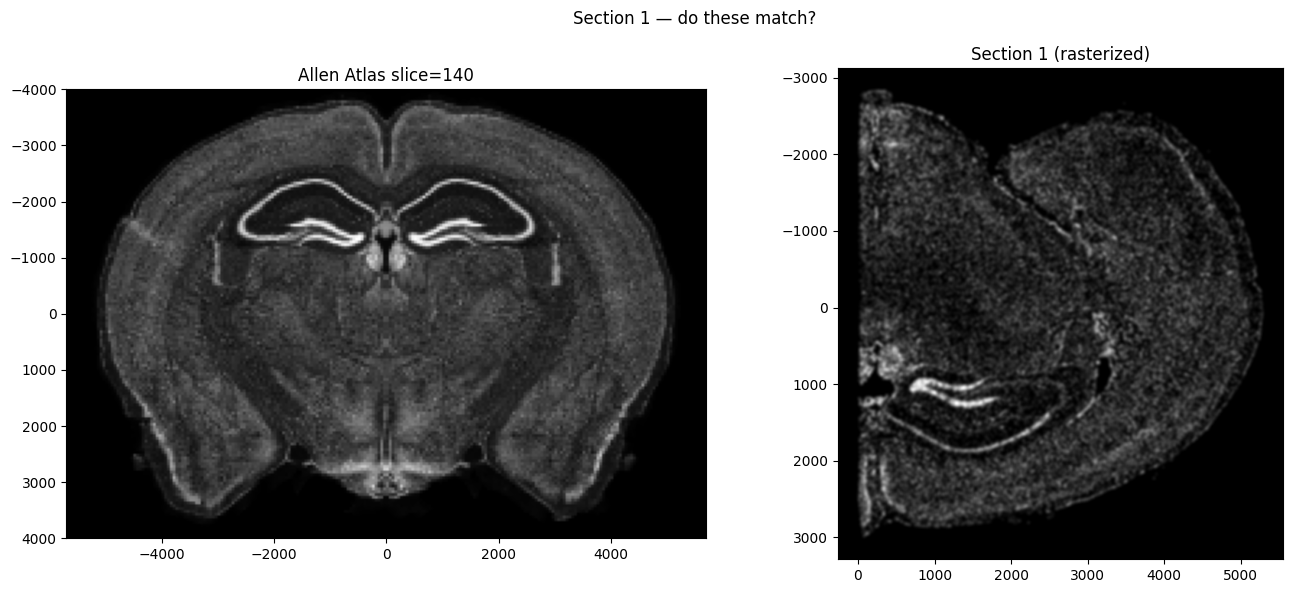

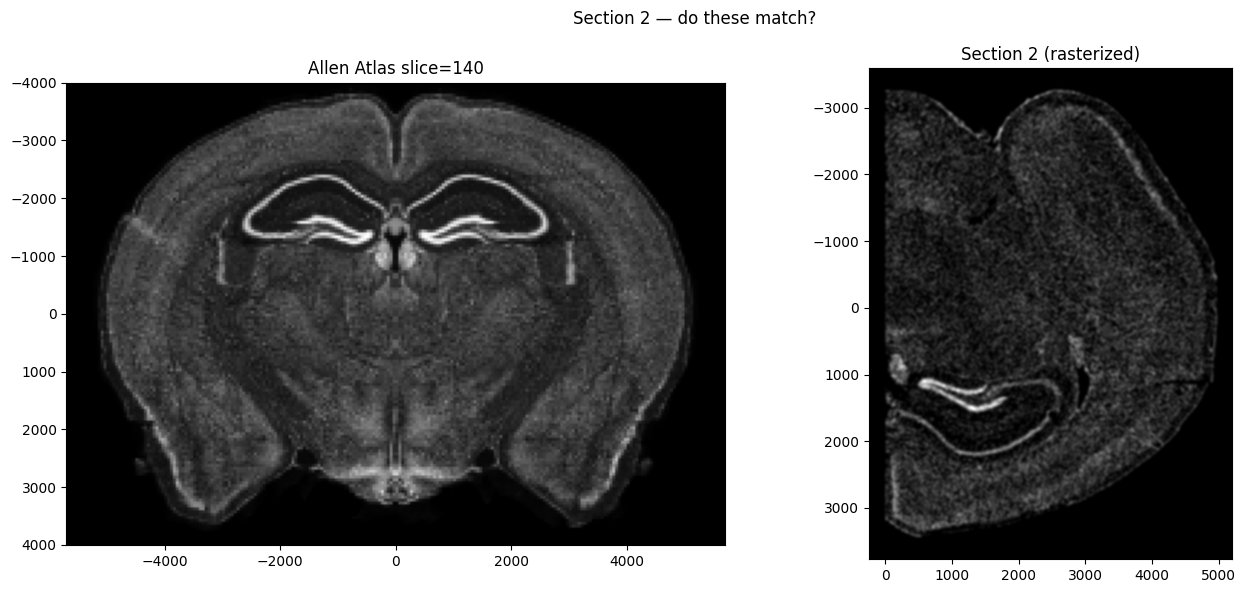

In [11]:
DX = 10       # rasterization resolution (µm)
BLUR = 1.0    # Gaussian blur sigma for rasterization

for i, ((x, y), atlas_slice) in enumerate(zip(coords, ATLAS_SLICES)):
    X_, Y_, W = STalign.rasterize(x, y, dx=DX, blur=BLUR, draw=False)
    W_img = W[0]

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].imshow(A_atlas[atlas_slice], extent=extentA, cmap='gray')
    ax[0].set_title(f'Allen Atlas slice={atlas_slice}')
    extent_target = (X_[0], X_[-1], Y_[0], Y_[-1])
    ax[1].imshow(W_img, extent=extent_target, cmap='gray')
    ax[1].set_title(f'Section {i+1} (rasterized)')
    ax[1].invert_yaxis()
    fig.suptitle(f'Section {i+1} — do these match?')
    plt.tight_layout()
    plt.show()

## 9. Define the alignment function

This function wraps the full STalign pipeline:
rasterize → set up affine → LDDMM → analyze → annotate AnnData.

In [12]:
def align_and_annotate(
    adata,
    x, y,
    imagefile,
    labelfile,
    namesdict,
    xA,
    A_atlas,
    atlas_slice,
    dx=10,
    blur=1.0,
    niter=2000,
    theta_deg=0.0,
    device='cpu',
    sigmaA=2.0,
    sigmaB=2.0,
    sigmaM=2.0,
    muA=(3, 3, 3),
    muB=(0, 0, 0),
    scale_x=0.9,
    scale_y=0.9,
    scale_z=0.9,
):
    """
    Align one section to the Allen Brain Atlas and annotate every cell.
    Follows the STalign tutorial exactly.
    """
    # ── Rasterize ────────────────────────────────────────────────────
    X_, Y_, W = STalign.rasterize(x, y, dx=dx, blur=blur, draw=False)
    W = W[0]

    # ── Prepare source (atlas) and target (ST) ───────────────────────
    xJ = [Y_, X_]
    J = W[None] / np.mean(np.abs(W))

    xI = xA
    I = A_atlas[None] / np.mean(np.abs(A_atlas), keepdims=True)
    I = np.concatenate((I, (I - np.mean(I)) ** 2))

    # ── Initial affine transform (exactly as tutorial) ───────────────
    theta0 = (np.pi / 180) * theta_deg

    T = np.array([
        -xI[0][atlas_slice],
        np.mean(xJ[0]),        # y: center on data (this is fine)
        0.0,                   # x: atlas midline at x=0 (where your data starts)
    ])

    scale_atlas = np.array([
        [scale_z, 0, 0],
        [0, scale_x, 0],
        [0, 0, scale_y],
    ])
    L = np.array([
        [1.0, 0.0, 0.0],
        [0.0, np.cos(theta0), -np.sin(theta0)],
        [0.0, np.sin(theta0),  np.cos(theta0)],
    ])
    L = np.matmul(L, scale_atlas)

    # ── Run LDDMM ───────────────────────────────────────────────────
    muA_t = torch.tensor(muA, device=device, dtype=torch.float64)
    muB_t = torch.tensor(muB, device=device, dtype=torch.float64)

    transform = STalign.LDDMM_3D_to_slice(
        xI, I, xJ, J,
        T=T, L=L,
        nt=4,
        niter=niter,
        device=device,
        sigmaA=sigmaA,
        sigmaB=sigmaB,
        sigmaM=sigmaM,
        muA=muA_t,
        muB=muB_t,
    )

    # ── Move everything to CPU ───────────────────────────────────────
    for key in transform:
        if isinstance(transform[key], torch.Tensor):
            transform[key] = transform[key].cpu()
        elif isinstance(transform[key], list):
            transform[key] = [t.cpu() if isinstance(t, torch.Tensor) else t 
                              for t in transform[key]]

    A_transform = transform['A']
    v = transform['v']
    xv = transform['xv']

    # ── Project atlas labels onto cells ──────────────────────────────
    df = STalign.analyze3Dalign(
        labelfile, xv, v, A_transform, xJ, dx,
        scale_x=scale_x, scale_y=scale_y,
        x=x, y=y, X_=X_, Y_=Y_,
        namesdict=namesdict, device='cpu',
    )

    # ── Write annotations into AnnData ───────────────────────────────
    adata.obs['allen_region_id']      = df['struct_id'].values
    adata.obs['allen_region_acronym'] = df['acronym'].values
    adata.obs['allen_coord0']         = df['coord0'].values
    adata.obs['allen_coord1']         = df['coord1'].values
    adata.obs['allen_coord2']         = df['coord2'].values

    return adata, transform, xI, I, xJ, J

## 10. Run alignment

We process one section at a time so you can inspect the results before
moving to the next.

### Section 1

Aligning section 1 (44,686 cells) to atlas slice 140...
Device: cuda:0



/nfs/team361/sb75/.venvs/stalign/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/nfs/team361/sb75/.venvs/stalign/lib/python3.10/site-packages/STalign/STalign.py:1616: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axE[2].set_yscale('log')
/nfs/team361/sb75/.venvs/stalign/lib/python3.10/site-packages/STalign/STalign.py:1725: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  A = torch.tensor(A)
/nfs/team361/sb75/.venvs/stalign/lib/python3.10/site-packages/STalign/STalign.py:1726: UserWarning: To copy construct from a tensor, it is recommended to use sourceTenso


Done!
CPU times: user 2min 29s, sys: 2.15 s, total: 2min 31s
Wall time: 2min 3s


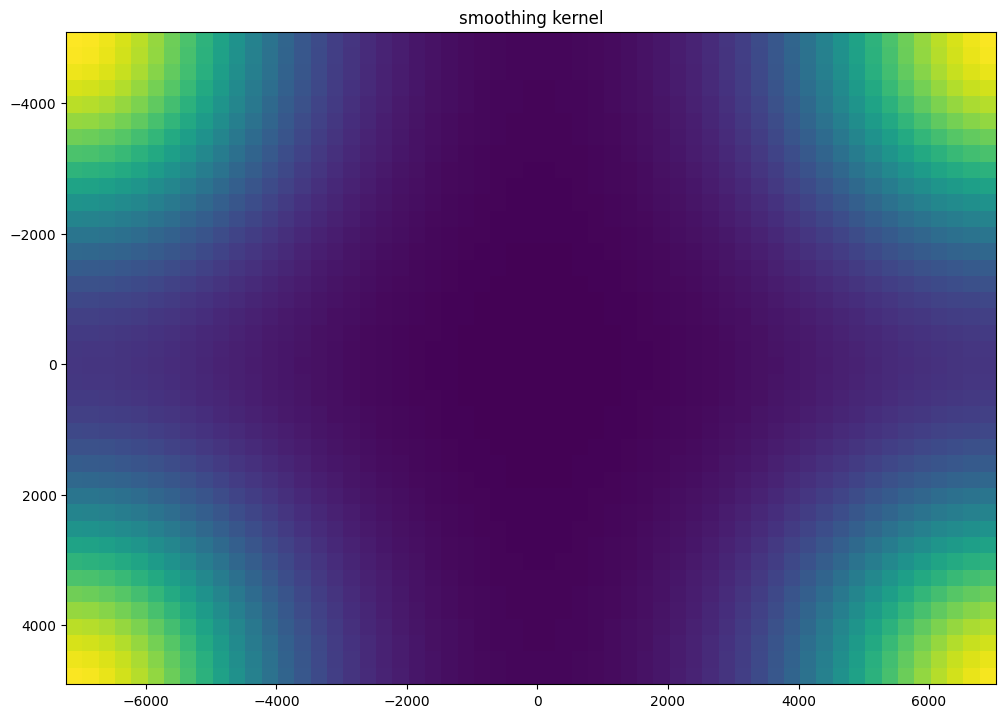

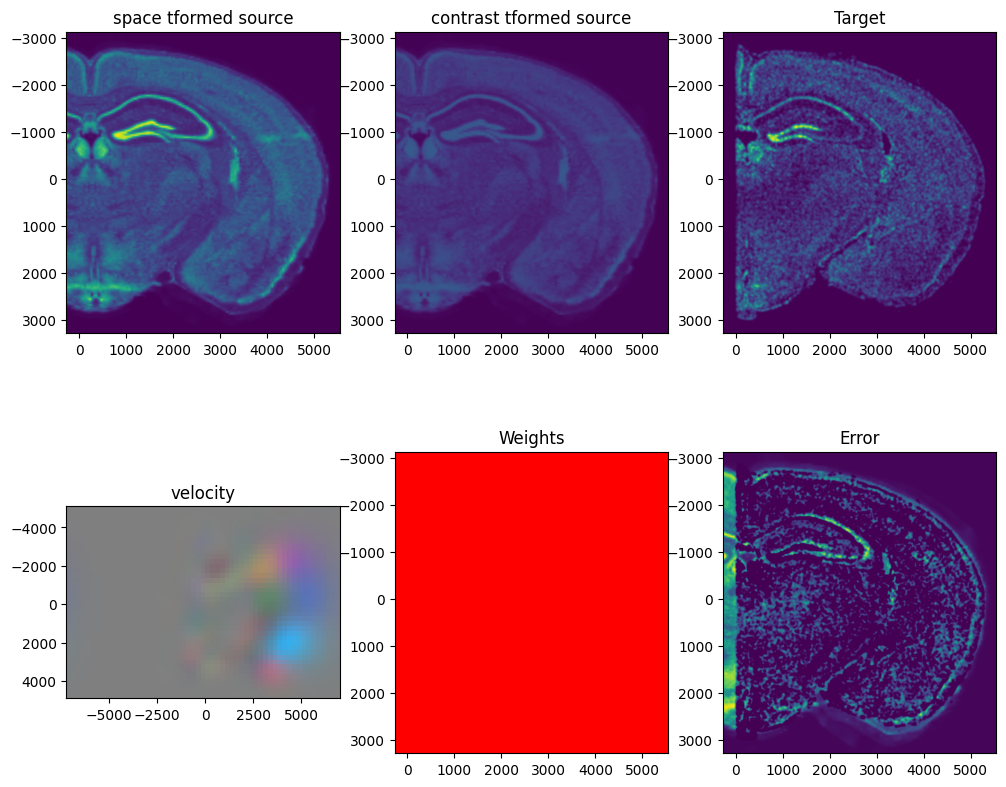

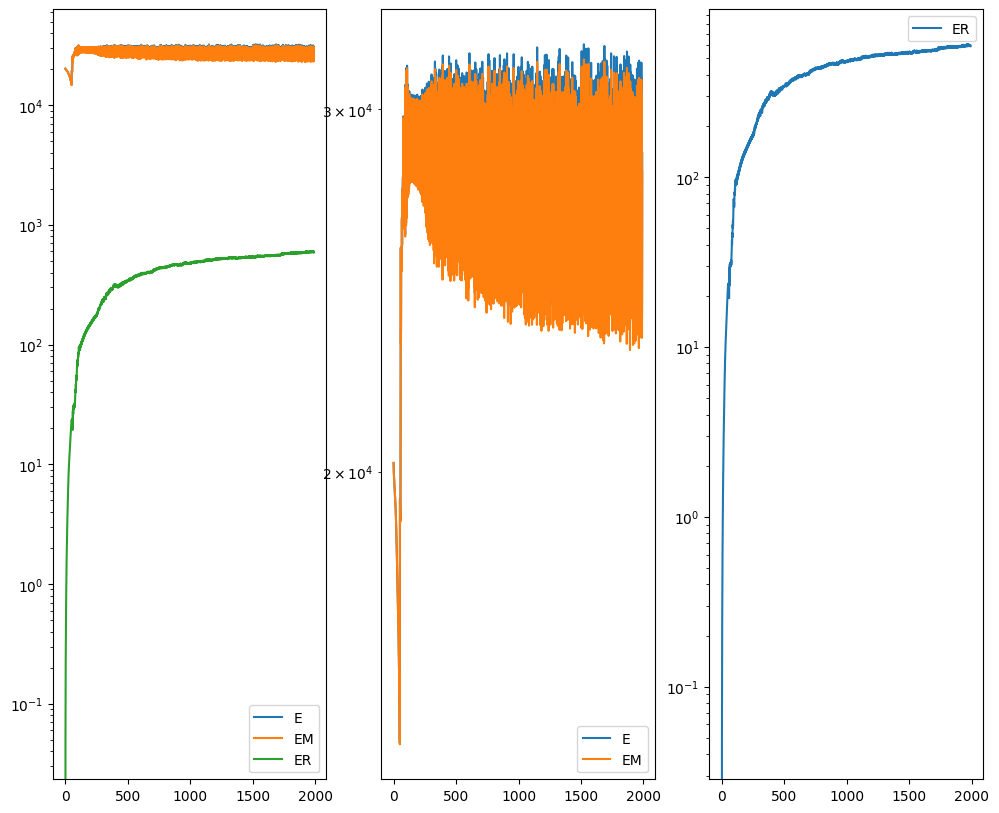

In [13]:
%%time

SECTION_IDX = 0
adata_i = adatas[SECTION_IDX]
x_i, y_i = coords[SECTION_IDX]
slice_i = ATLAS_SLICES[SECTION_IDX]

print(f'Aligning section {SECTION_IDX + 1} '
      f'({adata_i.shape[0]:,} cells) to atlas slice {slice_i}...')
print(f'Device: {DEVICE}')
print()

adata_i, transform, xI, I, xJ, J = align_and_annotate(
    adata=adata_i,
    x=x_i, y=y_i,
    imagefile=imagefile,
    labelfile=labelfile,
    namesdict=namesdict,
    xA=xA,
    A_atlas=A_atlas,
    atlas_slice=slice_i,
    niter=2000,
    theta_deg=0.0,
    device=DEVICE,
    sigmaM=2.0,
    sigmaA=2.0,
    sigmaB=2.0,
    muA=(3, 3, 3),
    muB=(0, 0, 0),
    scale_x=0.9,
    scale_y=0.9,
    scale_z=0.9,
)

adatas[SECTION_IDX] = adata_i
print('\nDone!')

## 11. Annotation summary

In [14]:
adata_i = adatas[SECTION_IDX]

total = len(adata_i)
labeled = (adata_i.obs['allen_region_id'] != 0).sum()
bg = total - labeled
n_regions = adata_i.obs.loc[
    adata_i.obs['allen_region_id'] != 0, 'allen_region_acronym'
].nunique()

print(f'Total cells:             {total:>8,}')
print(f'Cells with region label: {labeled:>8,}  ({100*labeled/total:.1f}%)')
print(f'Background (unlabeled):  {bg:>8,}  ({100*bg/total:.1f}%)')
print(f'Unique brain regions:    {n_regions:>8,}')

print('\nTop 20 brain regions by cell count:')
print(
    adata_i.obs.loc[
        adata_i.obs['allen_region_id'] != 0, 'allen_region_acronym'
    ].value_counts().head(20).to_string()
)

Total cells:               44,686
Cells with region label:   42,764  (95.7%)
Background (unlabeled):     1,922  (4.3%)
Unique brain regions:         171

Top 20 brain regions by cell count:
allen_region_acronym
CP            1602
DG-mo         1291
CA1           1239
MEA           1150
VPM           1123
PIR            954
VMH            943
MH             898
HY             854
SSp-bfd2/3     834
DMH            824
or             796
SSp-bfd6a      676
int            665
CA3            625
SSp-bfd5       619
LHA            610
RSPv2/3        604
LA             596
PO             594


## 12. QC — alignment overlay

Blue = your ST data. Red = aligned atlas. They should overlap well.

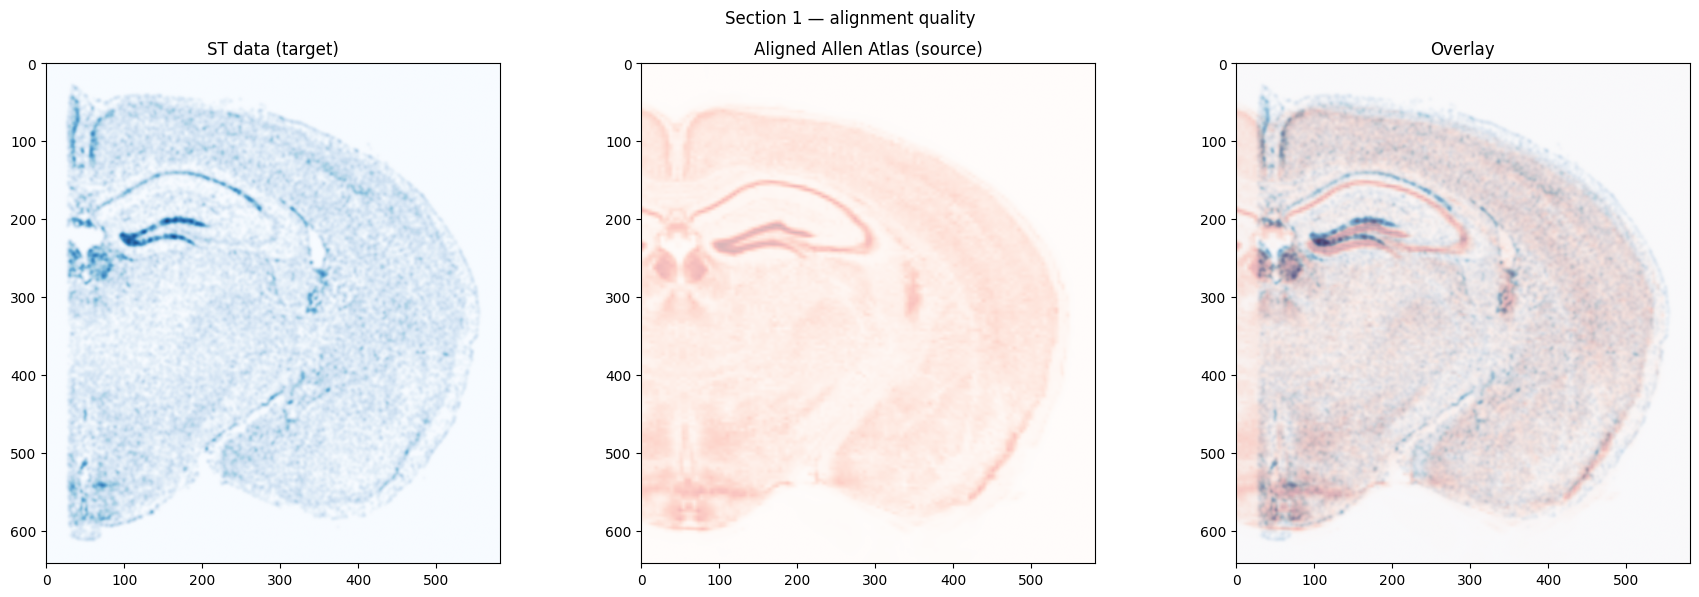

In [15]:
Xs = transform['Xs'].cpu()

It = torch.tensor(I, device='cpu', dtype=torch.float64)
AI = STalign.interp3D(xI, It, Xs.permute(3, 0, 1, 2), padding_mode='border')
Ishow_source = (
    (AI - torch.amin(AI, (1,2,3))[..., None, None])
    / (torch.amax(AI, (1,2,3)) - torch.amin(AI, (1,2,3)))[..., None, None, None]
).permute(1, 2, 3, 0).clone().detach().cpu()

Jt = torch.tensor(J, device='cpu', dtype=torch.float64)
Ishow_target = Jt.permute(1, 2, 0).cpu() / torch.max(Jt).item()

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(Ishow_target, cmap=mpl.cm.Blues, alpha=0.9)
ax[0].set_title('ST data (target)')
ax[1].imshow(Ishow_source[0, :, :, 0], cmap=mpl.cm.Reds, alpha=0.3)
ax[1].set_title('Aligned Allen Atlas (source)')
ax[2].imshow(Ishow_target, cmap=mpl.cm.Blues, alpha=0.9)
ax[2].imshow(Ishow_source[0, :, :, 0], cmap=mpl.cm.Reds, alpha=0.3)
ax[2].set_title('Overlay')
plt.suptitle(f'Section {SECTION_IDX + 1} — alignment quality')
plt.tight_layout()
plt.show()

## 13. QC — brain region map

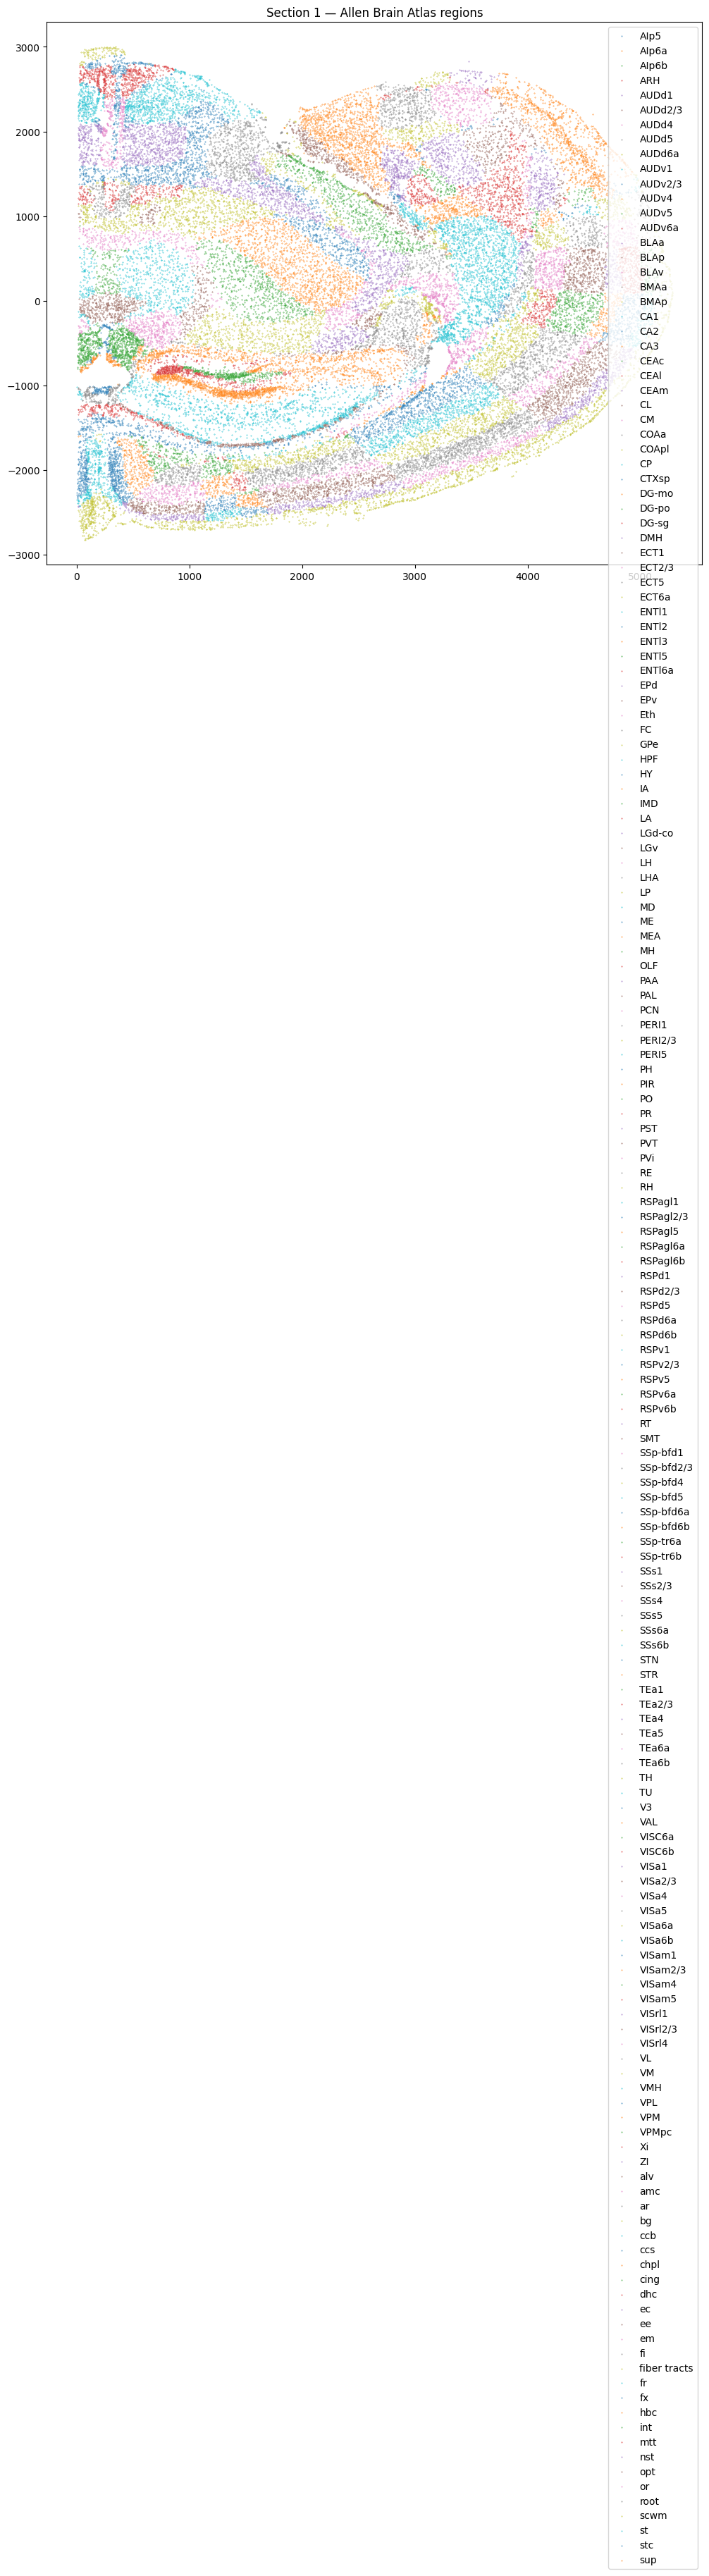

In [16]:
# STalign's built-in region plot
df_plot = pd.DataFrame({
    'x': x_i,
    'y': y_i,
    'struct_id': adata_i.obs['allen_region_id'].values,
    'acronym': adata_i.obs['allen_region_acronym'].values,
    'coord0': adata_i.obs['allen_coord0'].values,
    'coord1': adata_i.obs['allen_coord1'].values,
    'coord2': adata_i.obs['allen_coord2'].values,
})

STalign.plot_brain_regions(df_plot)
plt.title(f'Section {SECTION_IDX + 1} — Allen Brain Atlas regions')
plt.show()

## 14. QC — cells colored by region

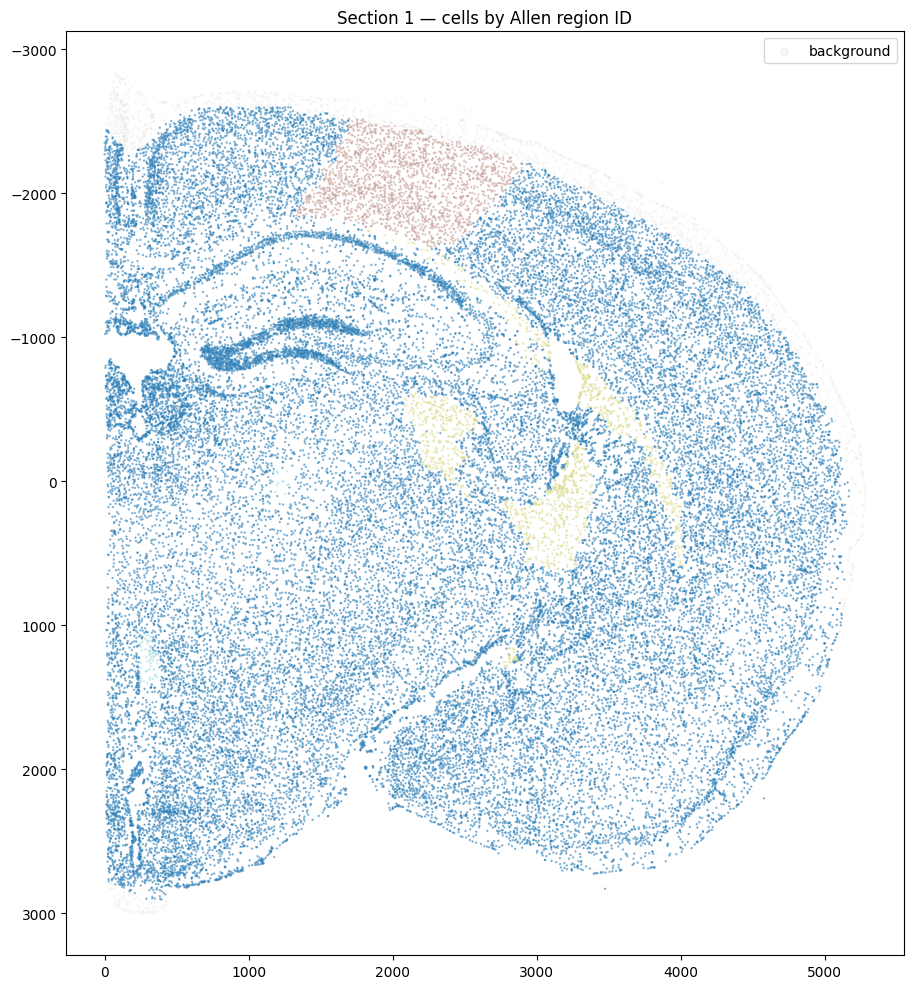

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

mask = adata_i.obs['allen_region_id'] != 0
ax.scatter(
    x_i[~mask], y_i[~mask],
    c='lightgray', s=0.3, alpha=0.2, label='background', rasterized=True,
)
scatter = ax.scatter(
    x_i[mask], y_i[mask],
    c=adata_i.obs.loc[mask, 'allen_region_id'].astype(int),
    s=0.5, alpha=0.5, cmap='tab20', rasterized=True,
)
ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_title(f'Section {SECTION_IDX + 1} — cells by Allen region ID')
ax.legend(markerscale=10)
plt.tight_layout()
plt.show()

## 15. Inspect specific brain regions (optional)

Use `plot_subset_brain_regions` to highlight particular regions.

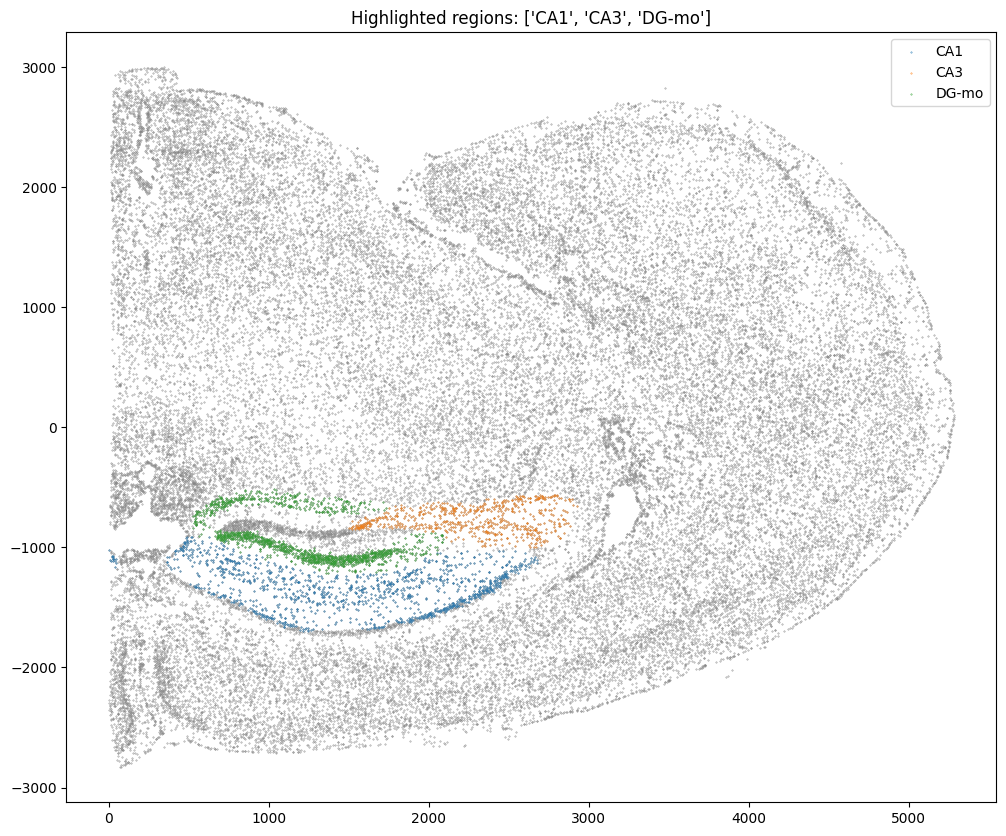

In [18]:
# Change these to regions of interest
regions_of_interest = ['CA1', 'CA3', 'DG-mo', 'VISp4', 'VISp5']

# Only plot if any of these regions are actually present
present = [r for r in regions_of_interest if r in adata_i.obs['allen_region_acronym'].values]
if present:
    STalign.plot_subset_brain_regions(df_plot, present)
    plt.title(f'Highlighted regions: {present}')
    plt.show()
else:
    print(f'None of {regions_of_interest} found in this section.')
    print('Available regions:', sorted(adata_i.obs['allen_region_acronym'].unique())[:30])

## 16. Process remaining sections

Run the loop below to align all remaining sections. You can also go back
to cell 10 and change `SECTION_IDX` to process them one at a time.

In [ ]:
%%time

for idx in range(len(adatas)):
    if 'allen_region_acronym' in adatas[idx].obs.columns:
        print(f'Section {idx + 1}: already annotated, skipping.')
        continue

    x_i, y_i = coords[idx]
    slice_i = ATLAS_SLICES[idx]
    print(f'\nAligning section {idx + 1} ({adatas[idx].shape[0]:,} cells) '
          f'to atlas slice {slice_i}...')

    adatas[idx], _, _, _, _, _ = align_and_annotate(
        adata=adatas[idx],
        x=x_i, y=y_i,
        imagefile=imagefile,
        labelfile=labelfile,
        namesdict=namesdict,
        xA=xA,
        A_atlas=A_atlas,
        atlas_slice=slice_i,
        niter=2000,
        device=DEVICE,
    )
    print(f'  Section {idx + 1} done!')

print('\nAll sections annotated!')

## 17. Save annotated AnnData objects

In [ ]:
for i, (adata, path) in enumerate(zip(adatas, ADATA_PATHS)):
    out_path = Path(path).stem + '_allen_annotated.h5ad'
    adata.write_h5ad(out_path)
    print(f'Section {i+1}: saved to {out_path}')
    
    # Quick summary
    labeled = (adata.obs['allen_region_id'] != 0).sum()
    n_reg = adata.obs.loc[
        adata.obs['allen_region_id'] != 0, 'allen_region_acronym'
    ].nunique()
    print(f'  {labeled:,}/{len(adata):,} cells labeled across {n_reg} regions')

## 18. Using annotations downstream

```python
# Filter to a specific brain region
hippocampus = adata[adata.obs['allen_region_acronym'].str.startswith('CA')]

# Differential expression by region
import scanpy as sc
sc.tl.rank_genes_groups(adata, groupby='allen_region_acronym', method='wilcoxon')

# Region composition
adata.obs['allen_region_acronym'].value_counts()

# Spatial plot colored by region (scanpy)
sc.pl.spatial(adata, color='allen_region_acronym', spot_size=10)
```

## Appendix: Tuning parameters

If the alignment looks off, try:

| Parameter | Default | What it does |
|---|---|---|
| `atlas_slice` | — | Coronal position in the atlas. This is the most important parameter. |
| `theta_deg` | 0 | Initial rotation (degrees). Set if tissue is rotated vs the atlas. |
| `niter` | 2000 | More iterations → better convergence, but slower. Try 3000–5000. |
| `dx` | 10 | Rasterization resolution (µm). Lower = finer, but more RAM. |
| `sigmaM` | 2.0 | Matching intensity std. Smaller = stricter matching. |
| `sigmaA` | 2.0 | Artifact intensity std. Increase if tissue has tears/folds. |
| `sigmaB` | 2.0 | Background intensity std. |
| `muA` | (3,3,3) | Mean artifact intensity. |
| `muB` | (0,0,0) | Mean background intensity. |
| `scale_x/y/z` | 0.9 | Initial atlas scaling. Adjust if atlas appears too big/small. |

Check the intensity histogram of your rasterized image to guide sigma/mu choices:
```python
plt.hist(J.ravel(), bins=100)
plt.xlabel('Intensity')
plt.show()
```